# 0_2 OCR 사용 방법

- [Gemini 이미지 이해 안내](https://ai.google.dev/gemini-api/docs/image-understanding)
- [Gemini OpenAI 호환 API 안내](https://ai.google.dev/gemini-api/docs/openai)

Gemini로 영수증 이미지의 내용을 JSON으로 읽고, 메뉴별 수량을 확인합니다.

`notebooks` 폴더에서 실행합니다. 환경 변수 `GEMINI_API_KEY`가 필요하며, 이미지는 Gemini API로 전송됩니다.

In [1]:
# uv pip install openai pillow

## 1. 모델 불러오기

기존 OpenAI 클라이언트를 Gemini 호환 API에 연결합니다. 모델은 API에서 실행됩니다.

In [2]:
import os
from pathlib import Path
from openai import OpenAI

# 1. 모델 준비: 환경 변수에 설정한 키로 Gemini에 연결합니다.
client = OpenAI(
    api_key=os.environ["GEMINI_API_KEY"],
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
)
model = "gemini-2.5-flash"
print("사용 모델:", model)

사용 모델: gemini-2.5-flash


## 2. Input 준비하기

첫 번째 영수증과 이미지 내용을 JSON으로 읽기 위한 지침을 준비합니다.

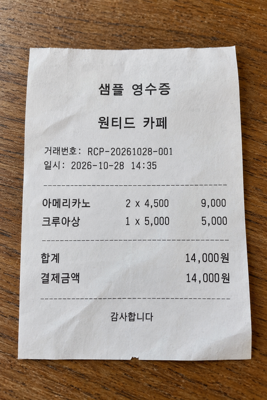

이미지: receipt-001.png


In [3]:
import base64
from IPython.display import display
from PIL import Image

# 1. 이미지 확인: 원본을 보존하고 화면에 보여 줄 크기만 줄입니다.
image_path = Path("../data/sample_receipts/receipt-001.png")
with Image.open(image_path) as image:
    preview = image.copy()
    preview.thumbnail((400, 400))
    display(preview)


print("이미지:", image_path.name)

In [4]:
# 1. 지침 준비: 읽기 어려운 내용은 추측하지 않도록 안내합니다.
prompt = """# 영수증 내용 읽기

이미지에 보이는 영수증 내용을 읽어 지정된 형식으로 반환합니다.
보이지 않거나 확실하지 않은 값은 추측하지 말고 null로 둡니다.
위 항목에 담지 않은 글자는 other_text에 담습니다."""
print(prompt)

# 영수증 내용 읽기

이미지에 보이는 영수증 내용을 읽어 지정된 형식으로 반환합니다.
보이지 않거나 확실하지 않은 값은 추측하지 말고 null로 둡니다.
위 항목에 담지 않은 글자는 other_text에 담습니다.


### 출력 스키마

영수증에서 읽을 항목과 자료형을 정의합니다. 읽지 못한 값은 `null`로 표시합니다.

In [5]:
from pydantic import BaseModel, Field


class ReceiptItem(BaseModel):
    """영수증에 적힌 메뉴 한 항목의 이름, 수량과 금액을 담습니다."""

    name: str | None = Field(description="영수증에 적힌 메뉴 이름, 읽지 못하면 null")
    quantity: int | None = Field(description="메뉴 수량, 읽지 못하면 null")
    unit_price: int | None = Field(description="메뉴 단가, 읽지 못하면 null")
    amount: int | None = Field(description="메뉴 금액, 읽지 못하면 null")


class Receipt(BaseModel):
    """영수증에서 읽은 거래 정보와 메뉴 목록을 담습니다."""

    store_name: str | None = Field(description="매장 이름, 읽지 못하면 null")
    receipt_number: str | None = Field(description="거래번호, 읽지 못하면 null")
    purchased_at: str | None = Field(description="영수증에 적힌 일시, 읽지 못하면 null")
    items: list[ReceiptItem] = Field(description="영수증에서 읽은 메뉴별 항목")
    total: int | None = Field(description="영수증 합계, 읽지 못하면 null")
    payment_amount: int | None = Field(description="결제금액, 읽지 못하면 null")
    other_text: list[str] = Field(description="다른 항목에 담지 않은 영수증의 글자")

## 3. Output 분석하기

이미지 전체 내용을 JSON으로 읽어 출력합니다. 원본과 비교해 잘못 읽은 내용이 없는지 확인합니다.

In [6]:
import json


def generate_receipt_json(image_path, prompt):
    """영수증 이미지와 지침을 받아, 읽은 내용을 JSON 객체로 돌려줍니다."""
    # 1. 입력 준비: 이미지 파일을 API에 보낼 문자열로 바꿉니다.
    image_base64 = base64.b64encode(image_path.read_bytes()).decode("utf-8")

    # 2. 모델 호출: 영수증 이미지와 지침을 보내 JSON 응답을 받습니다.
    response = client.beta.chat.completions.parse(
        model=model,
        response_format=Receipt,
        messages=[{
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_base64}"}},
            ],
        }],
    )

    # 3. 결과 반환: 스키마로 확인한 결과를 딕셔너리로 바꿉니다.

    return response.choices[0].message.parsed.model_dump()


# 4. 결과 확인: 읽은 영수증 내용을 출력합니다.
receipt = generate_receipt_json(image_path, prompt)
print(json.dumps(receipt, ensure_ascii=False, indent=2))

{
  "store_name": "원티드 카페",
  "receipt_number": "RCP-20261028-001",
  "purchased_at": "2026-10-28 14:35",
  "items": [
    {
      "name": "아메리카노",
      "quantity": 2,
      "unit_price": 4500,
      "amount": 9000
    },
    {
      "name": "크루아상",
      "quantity": 1,
      "unit_price": 5000,
      "amount": 5000
    }
  ],
  "total": 14000,
  "payment_amount": 14000,
  "other_text": [
    "샘플 영수증",
    "감사합니다"
  ]
}


## 4. 활용 테스트

읽은 JSON에서 메뉴별 수량을 확인하고 영수증 이미지와 비교합니다. 수량을 읽지 못한 항목은 확인 필요로 표시합니다.

In [7]:
# 1. 수량 확인: 첫 번째 영수증의 메뉴별 수량을 확인합니다.
for item in receipt["items"]:
    name = item["name"] or "이름 확인 필요"
    quantity = item["quantity"]
    print(f"{name}: {quantity}개" if quantity is not None else f"{name}: 수량 확인 필요")

# 2. 전체 수량: 읽지 못한 수량이 없을 때 주문 수량을 합산합니다.
quantities = [item["quantity"] for item in receipt["items"]]
if quantities and all(quantity is not None for quantity in quantities):
    print("총 주문 수량:", sum(quantities), "개")
else:
    print("총 주문 수량: 확인 필요")

아메리카노: 2개
크루아상: 1개
총 주문 수량: 3 개


### 두 번째 영수증 테스트

다른 영수증 이미지에도 같은 함수를 적용하고 읽은 JSON과 메뉴별 수량을 확인합니다.

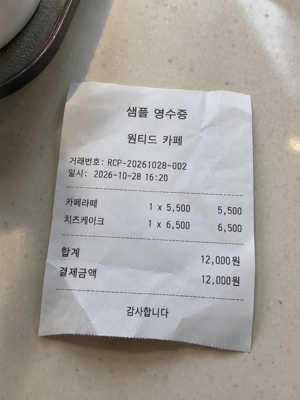

{
  "store_name": "원티드 카페",
  "receipt_number": "RCP-20261028-002",
  "purchased_at": "2026-10-28 16:20",
  "items": [
    {
      "name": "카페라떼",
      "quantity": 1,
      "unit_price": 5500,
      "amount": 5500
    },
    {
      "name": "치즈케이크",
      "quantity": 1,
      "unit_price": 6500,
      "amount": 6500
    }
  ],
  "total": 12000,
  "payment_amount": 12000,
  "other_text": [
    "샘플 영수증",
    "감사합니다"
  ]
}
카페라떼: 1개
치즈케이크: 1개
총 주문 수량: 2 개


In [8]:
# 1. 이미지 확인: 두 번째 영수증을 화면에 보여줍니다.
second_path = Path("../data/sample_receipts/receipt-002.png")
with Image.open(second_path) as image:
    preview = image.copy()
    preview.thumbnail((400, 400))
    display(preview)

# 2. 영수증 읽기: 다른 이미지도 JSON으로 변환합니다.
second_receipt = generate_receipt_json(second_path, prompt)

# 3. 결과 확인: 읽은 영수증 내용을 출력합니다.
print(json.dumps(second_receipt, ensure_ascii=False, indent=2))

# 4. 수량 확인: 두 번째 영수증의 메뉴별 수량을 확인합니다.
for item in second_receipt["items"]:
    name = item["name"] or "이름 확인 필요"
    quantity = item["quantity"]
    print(f"{name}: {quantity}개" if quantity is not None else f"{name}: 수량 확인 필요")

# 5. 전체 수량: 읽지 못한 수량이 없을 때 주문 수량을 합산합니다.
quantities = [item["quantity"] for item in second_receipt["items"]]
if quantities and all(quantity is not None for quantity in quantities):
    print("총 주문 수량:", sum(quantities), "개")
else:
    print("총 주문 수량: 확인 필요")